# 👻  **Taller 1 - Perceptrón & adaline**

<img src="https://www.udistrital.edu.co/themes/custom/versh/images/default/preloader.png" align="left" width="192px" height="192px"/>
<img align="left" width="0" height="192px" hspace="10"/>

> Juan Felipe Rodríguez Galindo  - **COD. 20261595004**
<br></br>
[![Juan Felipe Rodriguez Galindo](https://img.shields.io/badge/Juferoga-github-br?style=flat-square)](https://github.com/Juferoga)
[![License](https://img.shields.io/badge/License-GPL_V.3-blue?style=flat-square)](https://www.gnu.org/licenses/gpl-3.0.html)


Inteligencia Computacional

Desarrollo del taller propuesto en la clase de Inteligencia Computacional.

In [1]:
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

os.makedirs("figuras", exist_ok=True)

In [2]:
PARAMS = {
    "semilla": 2021,
    "umbral": 0.0,
    "umbrales": [0.0,0.5],
    "regla": 3,
    "alfa": 0.1,
    "alfas": [0.01, 0.1, 0.5, 1.0],
    "max_epocas": 100,
    "proporciones": [0.6,0.7,0.8,0.9],
    "ruta_banknote": "bibliografia/data_banknote_authentication.txt",
    # ADALINE
    "umbral_adaline": 0.5,
    "alfas_adaline": [0.001,0.01,0.05,0.1],
    "max_epocas_adaline": 200,
    "tol": 1e-6,
    # EXPERIMENTOS
    "compuertas": ["AND", "OR"],
    "entradas": [2, 3, 4],
    "reglas": [1, 2, 3],
    "epocas_curva": 20,
    "epocas_mse": 60,
    "alfas_mse": [0.001, 0.01, 0.05, 0.1, 0.5, 1.0],
}

## 1. Perceptrón simple
Entrada aumentada $X= [x, x_1, \dots, x_n]$; el 1 multiplica al peso $w_0$, bias.

- Salida: $z = W \cdot X$, y $Y = 1$ si $z \ge \theta$, si no $0$;
- Reglas: (1) $\Delta W = d\,X$ (2) $\Delta W= (d-Y)\,X$ (3) $\Delta W = \alpha (d-Y)\,X$
- Ajuste: $W^*=W+\delta W$ en cada ejemplo. Paro cuando una epoca termina sin que haya ningún error o también al llegar al máximo de épocas.

In [3]:
class Perceptron:
    def __init__(self, n_entradas, umbral=0.0, regla=3, alfa=0.1, max_epocas=100):
        self.n_entradas = n_entradas
        self.umbral = umbral
        self.regla = regla
        self.alfa = alfa
        self.max_epocas = max_epocas
        self.w = np.zeros(n_entradas+1) # W0 es el bias
        self.historial = [] # me va a guardar los errores

    def salida(self, x):
        X = np.r_[1,x] # [1, X1, ..., Xn]
        z = np.dot(self.w,X)
        return 1 if z >= self.umbral else 0
    
    def delta(self, X, d, y):
        if self.regla == 1:
            return d * X
        if self.regla == 2:
            return (d-y)*X
        if self.regla == 3:
            return self.alfa*(d-y)*X
        raise ValueError("La regla debe ser 1, 2 o 3.")

    def entrenar(self, datos, deseadas):
        self.historial = []
        for epoca in range(1, self.max_epocas +1):
            errores=0
            for x,d in zip(datos, deseadas):
                y = self.salida(x)
                if y != d:
                    errores += 1
                self.w = self.w + self.delta(np.r_[1,x],d,y)
            self.historial.append(errores)
            if errores == 0:
                return epoca ## Converge
        return self.max_epocas ## No converge
    
    def predecir(self, datos):
        return np.array([self.salida(x) for x in datos])

In [4]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
d = np.array([0,0,0,1]) # AND

for regla in PARAMS["reglas"]:
    p = Perceptron(X.shape[1], umbral=PARAMS["umbral"], regla=regla, alfa=PARAMS["alfa"], max_epocas=PARAMS["max_epocas"])
    epocas = p.entrenar(X,d)
    print(f"regla {regla}: {epocas} épocas, pesos {p.w}, últimos errores {p.historial[-5:]}")

regla 1: 100 épocas, pesos [100. 100. 100.], últimos errores [3, 3, 3, 3, 3]
regla 2: 6 épocas, pesos [-3.  2.  1.], últimos errores [3, 3, 2, 1, 0]
regla 3: 4 épocas, pesos [-0.2  0.2  0.1], últimos errores [2, 3, 3, 0]


## 2.Compuertas AND y OR de 2,3 y 4 entradas (punto 3)
Pruebo las reglas con dos umbrales ($\theta = 0$ y $0.5$) y, en la regla 3, varios valores de $\alpha$.

In [5]:
def compuerta(tipo, n):
    X = np.array(list(itertools.product([0, 1], repeat=n)))
    if tipo == "AND":
        d = np.all(X==1, axis=1).astype(int)
    elif tipo == "OR":
        d = np.any(X==1, axis=1).astype(int)
    else:
        raise ValueError("Tipo solo puede ser AND u OR")
    return X, d


In [6]:
compuerta("AND", 3)

(array([[0, 0, 0],
        [0, 0, 1],
        [0, 1, 0],
        [0, 1, 1],
        [1, 0, 0],
        [1, 0, 1],
        [1, 1, 0],
        [1, 1, 1]]),
 array([0, 0, 0, 0, 0, 0, 0, 1]))

In [7]:
filas = []

for tipo in PARAMS["compuertas"]:
    for n in PARAMS["entradas"]:
        X,d = compuerta(tipo, n)
        for regla in PARAMS["reglas"]:
            alfas = PARAMS["alfas"] if regla == 3 else [PARAMS["alfa"]]
            for umbral in PARAMS["umbrales"]:
                for alfa in alfas:
                    p = Perceptron(n, umbral=umbral, regla= regla, alfa=alfa, max_epocas=PARAMS["max_epocas"])
                    epocas = p.entrenar(X, d)
                    filas.append({
                        "compuerta":tipo,
                        "entradas":n,
                        "regla":regla,
                        "umbral":umbral,
                        "alfa":alfa,
                        "epocas":epocas,
                        "convergio":p.historial[-1] == 0,
                        "exactitud": np.mean(p.predecir(X) == d),
                        "pesos": np.round(p.w, 2),
                    })

In [8]:
tabla_compuertas = pd.DataFrame(filas)

In [9]:
tabla_compuertas

,compuerta,entradas,regla,umbral,alfa,epocas,convergio,exactitud,pesos
0,AND,2,1,0.0,0.10,100,False,0.25,"[100.0, 100.0, 100.0]"
1,AND,2,1,0.5,0.10,100,False,0.25,"[100.0, 100.0, 100.0]"
2,AND,2,2,0.0,0.10,6,True,1.00,"[-3.0, 2.0, 1.0]"
3,AND,2,2,0.5,0.10,6,True,1.00,"[-2.0, 2.0, 1.0]"
4,AND,2,3,0.0,0.01,6,True,1.00,"[-0.03, 0.02, 0.01]"
...,...,...,...,...,...,...,...,...,...
67,OR,4,3,0.0,1.00,6,True,1.00,"[-1.0, 1.0, 1.0, 1.0, 1.0]"
68,OR,4,3,0.5,0.01,6,True,1.00,"[0.36, 0.14, 0.15, 0.15, 0.15]"
69,OR,4,3,0.5,0.10,3,True,1.00,"[0.4, 0.1, 0.1, 0.2, 0.2]"
70,OR,4,3,0.5,0.50,6,True,1.00,"[0.0, 0.5, 0.5, 0.5, 0.5]"


In [10]:
tabla_compuertas.pivot_table(index=["compuerta", "entradas"], columns=["regla", "umbral"], values="epocas", aggfunc="min")

regla                 1        2       3    
umbral              0.0  0.5 0.0 0.5 0.0 0.5
compuerta entradas                          
AND       2         100  100   6   6   4   3
          3         100  100   7   7   3   4
          4         100  100  16  16  16   2
OR        2         100  100   4   4   4   2
          3         100  100   5   5   5   2
          4         100  100   6   6   6   3

In [11]:
tabla_compuertas[tabla_compuertas["regla"]== 3].pivot_table(index=["compuerta", "entradas"], columns=["umbral", "alfa"], values="epocas")

umbral               0.0                     0.5                 
alfa                0.01  0.10  0.50  1.00  0.01 0.10  0.50  1.00
compuerta entradas                                               
AND       2          6.0   4.0   6.0   6.0  18.0  3.0   6.0   6.0
          3          7.0   3.0   7.0   7.0  14.0  4.0   7.0   7.0
          4         16.0  17.0  16.0  16.0  11.0  2.0  16.0  16.0
OR        2          4.0   4.0   4.0   4.0  13.0  2.0   4.0   4.0
          3          5.0   5.0   5.0   5.0   8.0  2.0   5.0   5.0
          4          6.0   6.0   6.0   6.0   6.0  3.0   6.0   6.0

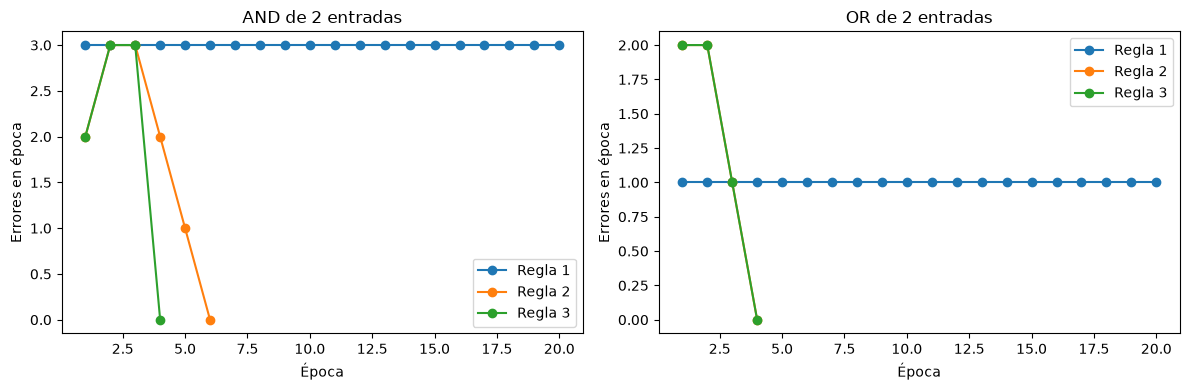

In [12]:
fig, ejes = plt.subplots(1,2, figsize=(12,4))
for eje, tipo in zip(ejes, PARAMS["compuertas"]):
    X,d = compuerta(tipo, 2)
    for regla in PARAMS["reglas"]:
        p = Perceptron(X.shape[1], umbral=PARAMS["umbral"], regla=regla, alfa=PARAMS["alfa"], max_epocas=PARAMS["epocas_curva"])
        p.entrenar(X,d)
        eje.plot(range(1, len(p.historial)+1), p.historial, marker="o", label=f"Regla {regla}")
    eje.set(title=f"{tipo} de 2 entradas", xlabel="Época", ylabel="Errores en época")
    eje.legend()
plt.tight_layout()
plt.savefig("figuras/perceptron_curvas_error.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Datos reales con particiones (60-40,70-30,80-20,90-10)
Replico la configuración de matlab fijando la semilla en 2021, realizo una permutación entre los indices y corto según la proporción, numpy no reparte igual así que serán equivalentes, pero no identicas.

In [13]:
def particionar(X, d, p, semilla):
    rng = np.random.default_rng(semilla)
    ind = rng.permutation(len(d))
    n_train = int(p * len(d))
    tr, te = ind[:n_train], ind[n_train:]
    return X[tr], d[tr], X[te], d[te]

In [14]:
def evaluar(crear_modelo, X, d, alfas, normalizar=False):
    filas = []
    for p in PARAMS["proporciones"]:
        X_tr, d_tr, X_te, d_te = particionar(X, d, p, PARAMS["semilla"])
        if normalizar: 
            media, desv = X_tr.mean(axis=0), X_tr.std(axis=0)
            X_tr, X_te = (X_tr - media) / desv, (X_te - media) / desv
        for alfa in alfas:
            m = crear_modelo(alfa)
            epocas = m.entrenar(X_tr, d_tr)
            filas.append({
                "particion": f"{round(p*100)}-{round((1-p)*100)}",
                "n_train": len(d_tr),
                "n_test": len(d_te),
                "alfa": alfa,
                "epocas": epocas,
                "exactitud_train": np.mean(m.predecir(X_tr)==d_tr),
                "exactitud_test": np.mean(m.predecir(X_te)==d_te),
            })
    return pd.DataFrame(filas)

In [15]:
iris = load_iris()
X_iris = iris.data
d_iris = (iris.target == 0).astype(int) # setosa 1, si no 0

per_iris = evaluar(lambda a: Perceptron(X_iris.shape[1], umbral=PARAMS["umbral"], regla=PARAMS["regla"], alfa=a, max_epocas=PARAMS["max_epocas"]),X_iris, d_iris, PARAMS["alfas"])

In [16]:
per_iris

,particion,n_train,n_test,alfa,epocas,exactitud_train,exactitud_test
0,60-40,90,60,0.01,2,1.0,1.0
1,60-40,90,60,0.10,2,1.0,1.0
2,60-40,90,60,0.50,2,1.0,1.0
3,60-40,90,60,1.00,2,1.0,1.0
4,70-30,105,45,0.01,2,1.0,1.0
5,70-30,105,45,0.10,2,1.0,1.0
6,70-30,105,45,0.50,2,1.0,1.0
7,70-30,105,45,1.00,2,1.0,1.0
8,80-20,120,30,0.01,2,1.0,1.0
9,80-20,120,30,0.10,2,1.0,1.0


In [17]:
datos_bn = np.loadtxt(PARAMS["ruta_banknote"], delimiter=",")
X_bn, d_bn = datos_bn[:,:4], datos_bn[:,4].astype(int)

print(X_bn.shape, np.bincount(d_bn))

per_bn = evaluar(
    lambda a: Perceptron(X_bn.shape[1], umbral=PARAMS["umbral"], regla=PARAMS["regla"], alfa=a, max_epocas=PARAMS["max_epocas"]),
    X_bn, d_bn, PARAMS["alfas"],
    normalizar=True
)

(1372, 4) [762 610]


In [18]:
per_bn

,particion,n_train,n_test,alfa,epocas,exactitud_train,exactitud_test
0,60-40,823,549,0.01,100,0.982989,0.972678
1,60-40,823,549,0.10,100,0.982989,0.972678
2,60-40,823,549,0.50,100,0.982989,0.972678
3,60-40,823,549,1.00,100,0.982989,0.972678
4,70-30,960,412,0.01,100,0.992708,0.990291
5,70-30,960,412,0.10,100,0.992708,0.990291
6,70-30,960,412,0.50,100,0.992708,0.990291
7,70-30,960,412,1.00,100,0.992708,0.990291
8,80-20,1097,275,0.01,100,0.989061,0.989091
9,80-20,1097,275,0.10,100,0.989061,0.989091


## 4. Adaline (7-12)


In [19]:
class Adaline:
    def __init__(self, n_entradas, umbral=0.5, alfa=0.01, max_epocas=200, tol=1e-6):
        self.n_entradas = n_entradas
        self.umbral = umbral
        self.alfa = alfa
        self.max_epocas = max_epocas
        self.tol = tol
        self.w = np.zeros(n_entradas + 1)
        self.historial = []

    def lineal(self, x):
        return np.dot(self.w, np.r_[1, x])

    def salida(self, x):
        return 1 if self.lineal(x) >= self.umbral else 0

    def predecir(self, datos):
        return np.array([self.salida(x) for x in datos])

    def entrenar(self, datos, deseadas):
        self.historial = []
        for epoca in range(1, self.max_epocas + 1):
            for x, d in zip(datos, deseadas):
                X = np.r_[1, x]
                y = np.dot(self.w, X)                      # salida lineal, sin escalón
                self.w = self.w + self.alfa * (d - y) * X  # regla delta (con sesgo)
            mse = np.mean([(d - self.lineal(x)) ** 2 for x, d in zip(datos, deseadas)])
            self.historial.append(mse)
            if not np.isfinite(mse):
                return epoca                               # diverge
            if epoca > 1 and abs(self.historial[-2] - mse) < self.tol:
                return epoca                               # se estabilizó
        return self.max_epocas                             # no convergió

In [20]:
filas = []
for tipo in PARAMS["compuertas"]:
    for n in PARAMS["entradas"]:
        X, d = compuerta(tipo, n)
        for alfa in PARAMS["alfas_adaline"]:
            a = Adaline(n, umbral=PARAMS["umbral_adaline"], alfa=alfa,
                        max_epocas=PARAMS["max_epocas_adaline"], tol=PARAMS["tol"])
            epocas = a.entrenar(X, d)
            filas.append({"compuerta": tipo, "entradas": n, "alfa": alfa, "epocas": epocas,
                          "mse_final": round(a.historial[-1], 4),
                          "exactitud": np.mean(a.predecir(X) == d), "pesos": np.round(a.w, 3)})

In [21]:
ada_compuertas = pd.DataFrame(filas)
ada_compuertas.pivot_table(index=["compuerta","entradas"], columns="alfa", values="exactitud")

alfa                 0.001   0.010   0.050   0.100
compuerta entradas                                
AND       2         0.7500  1.0000  1.0000  1.0000
          3         0.8750  0.8750  1.0000  1.0000
          4         0.9375  0.9375  0.9375  1.0000
OR        2         1.0000  1.0000  1.0000  1.0000
          3         1.0000  1.0000  0.8750  0.8750
          4         0.9375  0.9375  0.9375  0.9375

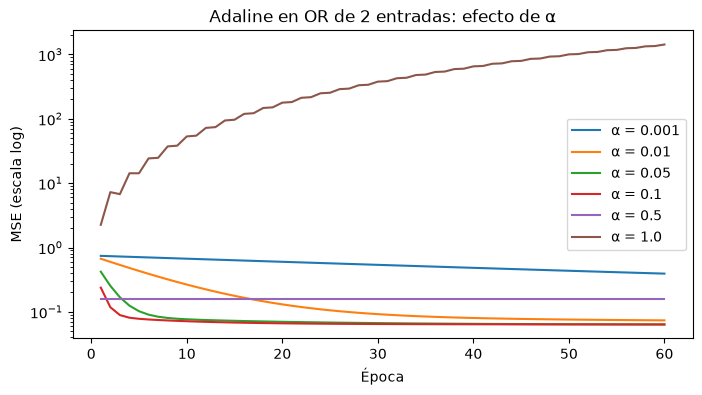

In [22]:
X, d = compuerta("OR", 2)
plt.figure(figsize=(8, 4))
for alfa in PARAMS["alfas_mse"]:
    a = Adaline(X.shape[1], umbral=PARAMS["umbral_adaline"], alfa=alfa, max_epocas=PARAMS["epocas_mse"], tol=0)  # tol=0: sin parada temprana, curva completa
    a.entrenar(X, d)
    plt.plot(range(1, len(a.historial) + 1), a.historial, label=f"α = {alfa}")
plt.yscale("log")
plt.xlabel("Época")
plt.ylabel("MSE (escala log)")
plt.title("Adaline en OR de 2 entradas: efecto de α")
plt.legend()
plt.savefig("figuras/adaline_mse_alfa.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
crear_ada = lambda a: Adaline(X_iris.shape[1], umbral=PARAMS["umbral_adaline"], alfa=a, max_epocas=PARAMS["max_epocas_adaline"], tol=PARAMS["tol"])
ada_iris = evaluar(crear_ada, X_iris, d_iris, PARAMS["alfas_adaline"], normalizar=True)
ada_iris

,particion,n_train,n_test,alfa,epocas,exactitud_train,exactitud_test
0,60-40,90,60,0.001,200,1.000000,1.000000
1,60-40,90,60,0.010,125,1.000000,1.000000
2,60-40,90,60,0.050,30,0.988889,1.000000
3,60-40,90,60,0.100,8,0.988889,0.983333
4,70-30,105,45,0.001,200,1.000000,1.000000
5,70-30,105,45,0.010,98,1.000000,1.000000
6,70-30,105,45,0.050,41,1.000000,1.000000
7,70-30,105,45,0.100,26,1.000000,1.000000
8,80-20,120,30,0.001,200,1.000000,1.000000
9,80-20,120,30,0.010,80,1.000000,1.000000


In [24]:
ada_bn = evaluar(crear_ada, X_bn, d_bn, PARAMS["alfas_adaline"], normalizar=True)
ada_bn

,particion,n_train,n_test,alfa,epocas,exactitud_train,exactitud_test
0,60-40,823,549,0.001,34,0.976914,0.965392
1,60-40,823,549,0.010,6,0.976914,0.963570
2,60-40,823,549,0.050,2,0.976914,0.965392
3,60-40,823,549,0.100,2,0.980559,0.970856
4,70-30,960,412,0.001,30,0.979167,0.963592
5,70-30,960,412,0.010,4,0.979167,0.961165
6,70-30,960,412,0.050,2,0.981250,0.970874
7,70-30,960,412,0.100,2,0.980208,0.973301
8,80-20,1097,275,0.001,28,0.979034,0.967273
9,80-20,1097,275,0.010,5,0.982680,0.974545


In [25]:
comparacion = pd.DataFrame({
    "Perceptron Iris": per_iris.groupby("particion")["exactitud_test"].max(),
    "Adaline Iris": ada_iris.groupby("particion")["exactitud_test"].max(),
    "Perceptron Banknote": per_bn.groupby("particion")["exactitud_test"].max(),
    "Adaline Banknote": ada_bn.groupby("particion")["exactitud_test"].max()
})
comparacion.round(4)

,Perceptron Iris,Adaline Iris,Perceptron Banknote,Adaline Banknote
particion,,,,
60-40,1.0,1.0,0.9727,0.9709
70-30,1.0,1.0,0.9903,0.9733
80-20,1.0,1.0,0.9891,0.9745
90-10,1.0,1.0,0.9855,0.9710


## Conclusiones
1. Las reglas 2 y 3 del perceptrón convergieron en todas las compuertas AND y OR (AND: 6, 7 y 16 épocas con 2, 3 y 4 entradas en la regla 2; OR: 4, 5 y 6). La regla 1 no convergió en ninguna: como ΔW = d·X nunca resta, los pesos solo crecen y la neurona termina respondiendo 1 para todo (25 % en AND-2).
2. Con θ = 0 y pesos iniciales en cero, α solo escala los pesos y no cambia la frontera. Las diferencias observadas vienen del redondeo en los empates z = 0. Con θ = 0.5, α sí importa: α = 0.01 tardó 18 épocas en AND-2 y α = 0.1, 3.
3. En Iris (Setosa contra el resto), el perceptrón convergió en 2 épocas con 100 % en test en las cuatro particiones. En banknote no convergió en 100 épocas (los datos no son perfectamente separables), pero alcanzó entre 97.3 % y 99.0 % en test.
4. Adaline necesita α pequeño: en OR-2, α = 0.05–0.1 llega al MSE mínimo (≈ 0.064), α = 0.5 oscila y α = 1 diverge. Al minimizar el MSE y no los errores, no clasifica perfectamente todas las compuertas (OR-4: 93.75 %).
5. En banknote, el perceptrón superó a Adaline en las cuatro particiones (mejor caso: 99.0 % contra 97.5 %); en Iris ambos llegaron a 100 %.

## Declaración de uso de IA
Usé Claude (Anthropic) para resolver dudas de teoría y para revisar y corregir errores. El registro del uso de la herramienta está en `registro_claude.csv`.
